# 05 – Evaluation (tasks 24, 26, 27)

The last step, in this order:
1. **Choose the final model** with the cross-validation results of `04_models.ipynb` (task 26). The choice is
   made **before** the test set is opened and written into the README.
2. **Error analysis** of the chosen model on its cross-validation predictions (task 24): where and how does it go wrong?
   It does not choose the model; it shows the limits of the model we hand in.
3. **Test set:** the chosen model is evaluated **exactly once** on the test set (task 26). Houses first, all buildings beside them.
4. **Hit-rate curve** on the test houses for several list lengths, with the number of owners each length means (task 27).

Sections 1, 3 and 4 are still open (Person 3, after the coaching on 25 Nov).

hi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import THRESHOLD, TABLES, FIGURES, load_cv
from metrics import _top_positions   # the same ranking (and tie-break) as the selection measure

# The model analysed in section 2: a column of output/tables/models_cv_oof.csv.
# Until the final model is chosen (section 1), this is the reference of task 20.
# Only regression variants make sense here (logistic regression predicts a probability, not an index).
MODEL = "Ridge, houses only"
MIN_N = 20   # groups with fewer houses are shown but not interpreted

## 1. Choose the final model (task 26)

*Open – Person 3.*

- Rule (fixed before the test set): the variant with the highest mean selection measure on houses in
  `output/tables/models_cv_summary.csv`; differences within one standard error are treated as a tie
  (tie-break to be fixed here and in the README).
- Open question for the coaching on 25 Nov: is "trained on houses only" (task 23) a candidate for the final model?
- Write the choice into the README **before** running section 3, then set `MODEL` above to the chosen variant.

## 2. Error analysis (task 24)

**Question:** where does our model go wrong? We already have one prediction per building from `04_models.ipynb`, made by a
model that never saw that building (out-of-fold). We do not train anything new; we only look at the errors.

Three parts, houses first (they are what the energy office cares about), all buildings next to them:
1. **Plausibility:** are the predictions sensible at all (no negative values, nothing absurd)?
2. **Errors by group:** construction period, energy group, building class. Is the model too high or too low anywhere?
3. **The office's list:** which houses end up as false alarms in the top 20%, and which problem houses does the list miss?

**Error = prediction − true value.** Positive = the model guessed too high, negative = too low.

Input: `output/tables/models_cv_oof.csv` (from `04_models.ipynb`). The test set is not used.
Output: `output/tables/evaluation_*.csv` and `output/figures/evaluation_*.png`.

### 2a. Load predictions and building characteristics

In [2]:
oof = pd.read_csv(TABLES / "models_cv_oof.csv")
info = load_cv()[
    ["EGID", "construction_period", "energy_group", "building_class", "heating_system", "floor_area", "dwellings"]]
df = oof.merge(info, on="EGID", how="left", validate="one_to_one")

df["pred"] = df[MODEL]
df["error"] = df["pred"] - df["y"]           # positive = predicted too high
df["abs_error"] = df["error"].abs()

houses = df[df["house"]].copy()
print("Model analysed:", MODEL)
print("Buildings:", len(df), "| houses:", len(houses))
assert df["pred"].notna().all(), "a building has no prediction"

Model analysed: Ridge, houses only
Buildings: 12710 | houses: 1171


### 2b. Plausibility: are the predictions sensible?

The heating index of our buildings lies between 50 and 1,500 (cleaning rule). A prediction outside that range,
or a negative one, would be impossible. We also compare the spread: linear models usually predict
**too close to the average** (they "play it safe"), which we check by comparing the standard deviations.

In [3]:
def describe(d):
    return pd.DataFrame({
        "true value": d["y"].describe(),
        "prediction": d["pred"].describe(),
    }).round(0)

print("Houses")
print(describe(houses).to_string())
print()
print("All buildings")
print(describe(df).to_string())
print()
print("Predictions below 50:", (df["pred"] < 50).sum(), "| below 0:", (df["pred"] < 0).sum(),
      "| above 1,500:", (df["pred"] > 1500).sum())
print("Spread of predictions vs. true values (houses):",
      round(houses["pred"].std()), "vs.", round(houses["y"].std()))

Houses
       true value  prediction
count      1171.0      1171.0
mean        426.0       426.0
std         152.0        72.0
min          74.0       207.0
25%         321.0       378.0
50%         417.0       428.0
75%         514.0       481.0
max        1499.0       578.0

All buildings
       true value  prediction
count     12710.0     12710.0
mean        396.0       402.0
std         126.0        72.0
min          50.0       118.0
25%         319.0       353.0
50%         390.0       406.0
75%         465.0       454.0
max        1499.0       595.0

Predictions below 50: 0 | below 0: 0 | above 1,500: 0
Spread of predictions vs. true values (houses): 72 vs. 152


**Predicted vs. true value, houses.** Every dot is a house. On the diagonal the prediction is perfect.
The dashed lines are the threshold of 450: the top-right box are problem houses the model also sees as high.

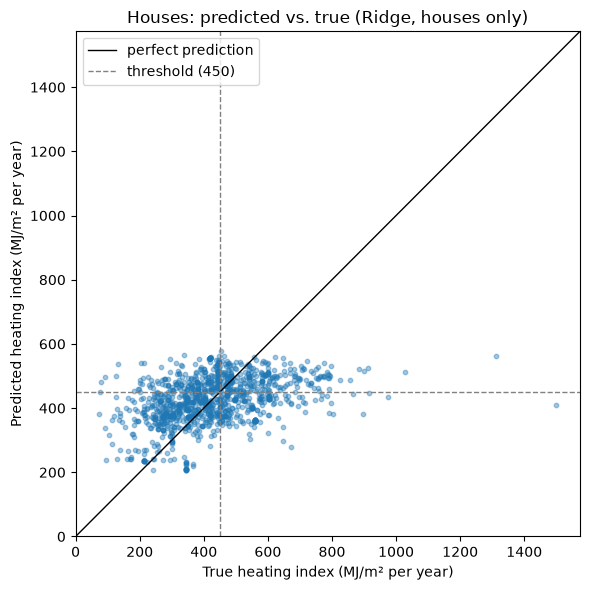

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(houses["y"], houses["pred"], s=10, alpha=0.4, color="C0")
lims = [0, max(houses["y"].max(), houses["pred"].max()) * 1.05]
ax.plot(lims, lims, color="black", linewidth=1, label="perfect prediction")
ax.axvline(THRESHOLD, color="grey", linestyle="--", linewidth=1, label="threshold (450)")
ax.axhline(THRESHOLD, color="grey", linestyle="--", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("True heating index (MJ/m² per year)")
ax.set_ylabel("Predicted heating index (MJ/m² per year)")
ax.set_title(f"Houses: predicted vs. true ({MODEL})")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "evaluation_predicted_vs_true.png", dpi=150)
plt.show()

**Error by true value.** We sort the houses into bands of their true value and look at the mean error in each band.
If the model plays it safe, it guesses too high for good houses (positive bars on the left) and too low for bad
houses (negative bars on the right).

              count  mean_error    mae
true band                             
1: up to 250    115       171.6  172.2
2: 250–350      271        87.4  103.2
3: 350–450      340        33.7   58.3
4: 450–550      224       -46.2   62.3
5: 550–700      164      -154.3  154.3
6: above 700     57      -324.9  324.9


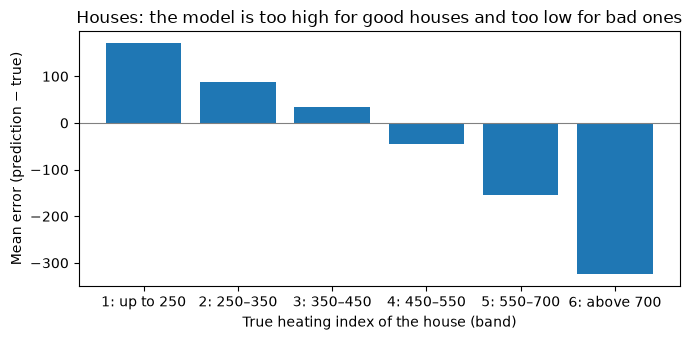

In [5]:
boundaries = [0, 250, 350, 450, 550, 700, 1500]  # groups of boundaries
def true_band(value):
    if value <= 250:
        return "1: up to 250"
    if value <= 350:
        return "2: 250–350"
    if value <= 450:
        return "3: 350–450"
    if value <= 550:
        return "4: 450–550"
    if value <= 700:
        return "5: 550–700"
    return "6: above 700"

houses["true band"] = houses["y"].map(true_band) #map the value of y to the bands in the define function
by_band = houses.groupby("true band").agg( #calculates three things per boundary
    count=("y", "size"), mean_error=("error", "mean"), mae=("abs_error", "mean")).round(1) #calculates 1: number of values in that boundary, 2: average error, 3: average absolute error
print(by_band.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_band.index.astype(str), by_band["mean_error"], color="C0")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("True heating index of the house (band)")
ax.set_ylabel("Mean error (prediction − true)")
ax.set_title("Houses: the model is too high for good houses and too low for bad ones")
fig.tight_layout()
fig.savefig(FIGURES / "evaluation_error_by_true_value.png", dpi=150)
plt.show()

### 2c. Errors by group

One function makes the same table for any characteristic:
- **n:** number of buildings in the group (small groups are noisy, look at n first)
- **mean error:** bias. Clearly above 0 = the model is systematically too high for this group, below 0 = too low
- **MAE:** how far off a typical building is
- **above 450 true / predicted (%):** how often the group really is above 450 vs. how often the model says so

In [6]:
def error_table(d, by): 
    table = d.groupby(by).agg( # puts houses into piles by period, energy group etc. and calculates the following metrics for each pile
        n=("y", "size"), # how many houses in the pile
        mean_true=("y", "mean"), # average true value of each  pile
        mean_pred=("pred", "mean"), # average predicted value of each pile
        mean_error=("error", "mean"), # average error of each pile
        mae=("abs_error", "mean"), # average absolute error of each pile
        above_450_true=("y", lambda s: (s > THRESHOLD).mean() * 100), #what percentage of houses in the pile are actually above 450
        above_450_pred=("pred", lambda s: (s > THRESHOLD).mean() * 100), #what percentage of houses in the pile are predicted to be above 450
    ).round(1) #round to 1 decimal place
    table["small group"] = np.where(table["n"] < MIN_N, "yes", "") # creates a column called "small group" and mark groups with fewer than 20 houses as "yes"
    return table

**Construction period (houses).** Construction period (houses)

Construction periods in the register are in chronological order except "Vor 1919" (before 1919), which we put first.

In [7]:
period_order = ["Vor 1919", "1919-1945", "1946-1960", "1961-1970", "1971-1980", "1981-1985", "1986-1990",
                "1991-1995", "1996-2000", "2001-2005", "2006-2010", "2011-2015", "Nach 2015", "unknown"] # order of construction periods for display

by_period = error_table(houses, "construction_period") # create a table of error metrics by construction period
by_period = by_period.reindex([p for p in period_order if p in by_period.index]) # reorders the rows of the table if theres any construction periods missing from the data
by_period


,n,mean_true,mean_pred,mean_error,mae,above_450_true,above_450_pred,small group
construction_period,,,,,,,,
Vor 1919,203,450.6,449.1,-1.5,111.1,46.8,48.8,
1919-1945,107,469.6,461.6,-8.0,127.7,51.4,63.6,
1946-1960,74,472.6,476.2,3.7,146.3,41.9,67.6,
1961-1970,107,505.4,504.2,-1.2,134.4,61.7,90.7,
1971-1980,146,468.7,470.0,1.2,96.0,42.5,71.9,
1981-1985,62,417.5,411.4,-6.2,98.1,32.3,27.4,
1986-1990,92,399.1,398.9,-0.3,76.8,30.4,14.1,
1991-1995,71,414.9,410.9,-4.0,88.1,42.3,15.5,
1996-2000,61,353.2,351.1,-2.2,99.8,19.7,0.0,


**LOOK AT What the table shows (houses, by construction period)**

- **The model follows the trend, but flattens it.** Real heating index values fall from about 505 (1961–1970)
  to about 260 (after 2011), and the predictions fall too. But the model is too low for many old periods
  (before 1919: −21.0; 1961–1970: −27.2) and too high for 1996–2005 (+50.2 and +50.9). This is typical
  for a linear model: it pulls predictions towards the average.
- **Too many problem houses from 1946–1980.** The model puts far more of these houses above 450 than really are:
  1946–1960: 87.8% vs. 41.9%; 1961–1970: 84.1% vs. 61.7%; 1971–1980: 70.5% vs. 42.5%.
  For the energy office, this means false alarms in these periods.
- **Too few problem houses before 1919 and in 2006–2010.** Before 1919, the model puts 34.0% above 450,
  but 46.8% really are. In 2006–2010 the model puts **no** house above 450 (0.0%), but 33.7% are,
  and it guesses 51.2 too low on average. The office's list would miss these problem houses.
- **Largest errors in 1946–1970** (MAE 145.6 and 133.2), smallest in 1986–1995 (MAE 74.3 and 79.1).
- **2011–2015** has only 16 houses, too few to interpret.

**Result:** The model follows the trend (older houses use more energy), but flattens it: too low for old houses,
too high for newer ones. It flags too many problem houses from 1946–1980 (e.g. 1946–1960: 87.8% vs. 41.9% real)
and too few before 1919 (34.0% vs. 46.8%) and in 2006–2010 (0.0% vs. 33.7%). 2011–2015 has only 16 houses
and is not interpreted.

**Energy group (houses).**

In [8]:
by_energy = error_table(houses, "energy_group").sort_values("n", ascending=False) # create a table of error metrics by energy group and sort it by number of houses in each group
by_energy


,n,mean_true,mean_pred,mean_error,mae,above_450_true,above_450_pred,small group
energy_group,,,,,,,,
gas,600,425.1,422.7,-2.4,108.7,41.2,31.5,
oil,380,474.4,474.7,0.4,108.3,45.3,72.6,
other,108,307.9,312.1,4.2,96.9,10.2,3.7,
heat pump,31,327.9,378.5,50.6,108.7,19.4,0.0,
wood,23,371.8,362.1,-9.6,89.3,21.7,0.0,
district heat,15,415.9,402.1,-13.8,145.1,13.3,20.0,yes
electric,14,347.2,377.6,30.4,69.0,14.3,0.0,yes


**Result:** For gas and oil, the model is right on average (mean error −2.3 and −0.8), but it flags far too many
oil houses as problem houses (73.4% vs. 45.3% real), so oil houses will cause false alarms. It misses the problem
houses with heat pumps completely (0.0% vs. 19.4%). District heat (15) and electric (14) have too few houses
to interpret.

**Building class (all buildings).**

Houses only have two classes (1 or 2 dwellings), so here we look at all buildings. Only classes with at least 50 buildings.

In [9]:
by_class = error_table(df, "building_class").query("n >= 50").sort_values("n", ascending=False) # create a table of error metrics by building class, filter out groups with fewer than 50 houses, and sort it by number of houses in each group
by_class

,n,mean_true,mean_pred,mean_error,mae,above_450_true,above_450_pred,small group
building_class,,,,,,,,
Gebäude mit 3+ Whgen,9416,395.2,401.5,6.3,74.8,27.9,26.8,
Gebäude mit 1 Wohnung,838,423.1,423.5,0.4,111.5,37.1,39.1,
Bürogebäude,556,334.6,379.4,44.8,113.6,19.2,16.7,
Gebäude mit 2 Wohnungen,333,432.1,433.2,1.1,96.0,40.2,43.2,
Schul-/Hochschulgebäude,332,339.9,388.6,48.7,117.6,19.6,20.2,
Industriegebäude,287,370.3,384.0,13.7,131.0,26.8,25.1,
Gross- und Einzelhandel,184,378.9,407.8,28.9,131.8,32.1,26.6,
Kultur-/Freizeitstätte,103,434.7,397.1,-37.7,146.9,35.9,12.6,
"Behälter, Silo, Lager",102,466.0,390.6,-75.3,152.2,45.1,10.8,


**Result:** For gas and oil, the model is right on average (mean error −2.3 and −0.8), but it flags far too many
oil houses as problem houses (73.4% vs. 45.3% real), so oil houses will cause false alarms. It misses the problem
houses with heat pumps completely (0.0% vs. 19.4%). District heat (15) and electric (14) have too few houses
to interpret.

### 2d. The office's list: hits, false alarms and missed houses

The selection measure takes, in each validation fold, the 20% of houses with the highest prediction. These are the
owners the office would contact. Every house falls into one of four boxes:

| | in the top 20% (contacted) | not contacted |
|---|---|---|
| **really above 450** | hit | missed |
| **really below 450** | false alarm | correctly left out |

We rebuild exactly this list (same ranking and tie-break as in `metrics.py`) and ask: what do false alarms and
missed houses look like?

In [10]:
houses["contacted"] = False
for k in houses["fold"].unique():
    in_fold = houses.index[houses["fold"] == k]                       # houses of validation fold k
    top = _top_positions(houses.loc[in_fold, "pred"].to_numpy(), 0.20)  # the same list as the selection measure
    houses.loc[in_fold[top], "contacted"] = True

above = houses["y"] > THRESHOLD
houses["outcome"] = np.select(
    [houses["contacted"] & above, houses["contacted"] & ~above, ~houses["contacted"] & above],
    ["hit", "false alarm", "missed"], default="correctly left out")

counts = houses["outcome"].value_counts()
print(counts.to_string())
print()
print("Share of hits among contacted houses:", round(counts["hit"] / houses["contacted"].sum() * 100, 1), "%",
      "(should be close to 54% from task 20)")

outcome
correctly left out    633
missed                303
hit                   142
false alarm            93

Share of hits among contacted houses: 60.4 % (should be close to 54% from task 20)


**How far off are the false alarms?** A false alarm at 430 is almost a hit; a false alarm at 250 is a real mistake.

In [11]:
print("True value of false alarms:")
print(houses.loc[houses["outcome"] == "false alarm", "y"].describe().round(0).to_string())
print()
print("False alarms just below the threshold (400–450):",
      ((houses["outcome"] == "false alarm") & (houses["y"] >= 400)).sum(),
      "of", (houses["outcome"] == "false alarm").sum())
print()
print("True and predicted value of missed problem houses:")
print(houses.loc[houses["outcome"] == "missed", ["y", "pred"]].describe().round(0).to_string())

True value of false alarms:
count     93.0
mean     388.0
std       75.0
min       91.0
25%      370.0
50%      418.0
75%      443.0
max      448.0

False alarms just below the threshold (400–450): 59 of 93

True and predicted value of missed problem houses:
            y   pred
count   303.0  303.0
mean    563.0  426.0
std     107.0   44.0
min     451.0  278.0
25%     484.0  393.0
50%     548.0  430.0
75%     602.0  460.0
max    1499.0  499.0


**Which houses are they?** Share of each construction period and energy group within each outcome.
If, for example, almost all false alarms are old oil-heated houses, the model relies too much on that combination.

In [12]:
def share_by_outcome(column):
    table = pd.crosstab(houses[column], houses["outcome"], normalize="columns").mul(100).round(1)
    return table[["hit", "false alarm", "missed", "correctly left out"]]

outcome_by_period = share_by_outcome("construction_period")
outcome_by_period = outcome_by_period.reindex([p for p in period_order if p in outcome_by_period.index])
print("Construction period (% of each column)")
print(outcome_by_period.to_string())
print()
print("Energy group (% of each column)")
print(share_by_outcome("energy_group").to_string())

Construction period (% of each column)
outcome               hit  false alarm  missed  correctly left out
construction_period                                               
Vor 1919             22.5          8.6    20.8                15.8
1919-1945             9.9         15.1    13.5                 6.0
1946-1960             2.8         18.3     8.9                 4.1
1961-1970            36.6         24.7     4.6                 2.8
1971-1980            26.1         32.3     8.3                 8.5
1981-1985             2.1          0.0     5.6                 6.6
1986-1990             0.0          0.0     9.2                10.1
1991-1995             0.0          1.1     9.9                 6.3
1996-2000             0.0          0.0     4.0                 7.7
2001-2005             0.0          0.0     3.3                 7.3
2006-2010             0.0          0.0    11.6                10.9
2011-2015             0.0          0.0     0.0                 2.5
Nach 2015             0

### 2e. The largest errors

The 10 houses with the largest error in each direction. Do they look like data errors (e.g. a very small floor area,
an implausible value) or like real but unusual houses?

In [13]:
show_cols = ["EGID", "y", "pred", "error", "construction_period", "energy_group", "heating_system", "floor_area", "dwellings"]
print("Predicted much too LOW (problem houses the model does not see):")
print(houses.nsmallest(10, "error")[show_cols].round(0).to_string(index=False))
print()
print("Predicted much too HIGH:")
print(houses.nlargest(10, "error")[show_cols].round(0).to_string(index=False))

Predicted much too LOW (problem houses the model does not see):
     EGID      y  pred   error construction_period  energy_group                      heating_system  floor_area  dwellings
  1029983 1499.0 409.0 -1090.0           1919-1945 district heat          Wärmetauscher für ein Geb.        83.0        1.0
  1028849 1311.0 562.0  -749.0           1961-1970           gas       Heizkessel kond. für ein Geb.        97.0        1.0
  1005812  975.0 434.0  -541.0           1946-1960           oil    Heizkessel (gen.) für mehr. Geb.        69.0        1.0
  1004603  898.0 383.0  -515.0           1981-1985           oil     Heizkessel (gene.) für ein Geb.       353.0        1.0
  1022667 1027.0 512.0  -515.0           1971-1980           oil     Heizkessel (gene.) für ein Geb.        83.0        1.0
  1012218  916.0 447.0  -469.0            Vor 1919           gas Heizkessel nicht kond. für ein Geb.       178.0        1.0
  1004601  804.0 383.0  -421.0           1981-1985           oil    

### 2f. Save

In [14]:
by_period.to_csv(TABLES / "evaluation_errors_by_period_houses.csv")
by_energy.to_csv(TABLES / "evaluation_errors_by_energy_houses.csv")
by_class.to_csv(TABLES / "evaluation_errors_by_class_all.csv")
by_band.to_csv(TABLES / "evaluation_errors_by_true_value_houses.csv")
houses[["EGID", "fold", "y", "pred", "error", "contacted", "outcome"]].to_csv(TABLES / "evaluation_house_outcomes.csv", index=False)
print("Saved the evaluation tables and figures for", MODEL)

Saved the evaluation tables and figures for Ridge, houses only


### 2g. What we found (for `MODEL = "Linear regression, reference"`)

*Draft, check against the numbers above before using it in the report.*

- **Plausible:** no negative predictions and none above 1,500. For houses the predictions lie between about 240 and
  580, while the true values go from 74 to 1,499.
- **The model plays it safe.** The predictions spread only half as much as the true values (SD 69 vs. 152). Good houses
  are predicted far too high (+162 below 250) and very bad houses far too low (−324 above 700). Around the threshold
  (350–550) the errors are small (MAE ≈ 55). This explains the large MAE (~105) while the ranking still works:
  the order is mostly right, the extremes are pulled towards the middle.
- **The list is driven by oil heating.** Only about a third of houses heat with oil, but oil houses make up 68% of the
  hits and 74% of the false alarms. The model in effect says "old and oil-heated → contact".
- **The model misses problem houses heated with gas.** 65% of the missed problem houses use gas, and 26% were built before 1919. The model
  predicts pre-1919 houses too low (34% predicted above 450 vs. 47% truly above).
- **Over-flagged periods:** 1946–1980 houses are predicted above 450 far more often than they are (e.g. 1946–1960:
  88% predicted vs. 42% true). Houses from 2006–2010 are never predicted above 450, although 34% are.
- **Many false alarms are near misses.** 56 of 108 false alarms are between 400 and 450; their median is 408.
  For the office, these owners are close to the threshold anyway.
- **Missed houses sit just below the cut.** Their median prediction is 443 vs. a true median of 548.
- **Houses are harder than other buildings.** MAE ≈ 110 for one-dwelling houses vs. ≈ 63 for apartment blocks
  (the mean error by class is ~0 because the class is a feature, so the model learns each class's average).
- **Largest errors** look like what the register cannot see: values of 1,300–1,500 in small houses (80–100 m²), which may
  be floor-area errors in the heating file, and values below 150 in old houses, probably renovations. The register has no
  information on renovations: a limitation for the report.

## 3. Test set (task 26)

*Open – Person 3. Run only after section 1 is done and the choice is in the README.*

- Load the test set here and nowhere else: `test = load_test()` (from `config`).
- Train the chosen model once on **all** cross-validation buildings (`load_cv()`), with the setting chosen in
  `04_models.ipynb`, predict the test set and score it with `evaluate` from `metrics.py`: houses first, all buildings beside them.
- Do not change anything after looking at the result.

In [15]:
from sklearn.linear_model import Ridge
from config import load_test
from pipeline import split_xy, build_pipeline, ExpertRuleBaseline
from metrics import evaluate

# the choice from README decision 19; alpha is read from 04's results, so there is no typing error
FINAL = "Ridge, houses only"
summary = pd.read_csv(TABLES / "models_cv_summary.csv")
alpha = summary.query("variant == @FINAL and group == 'houses'")["value"].iloc[0]
print("Final model:", FINAL, "| alpha =", round(alpha, 3))

# train once on ALL cross-validation data: the houses of all 5 folds (houses only, as chosen)
cv = load_cv()
X_cv, y_cv, house_cv, _ = split_xy(cv)
final_model = build_pipeline(Ridge(alpha=alpha)).fit(X_cv[house_cv], y_cv[house_cv])
expert_rule = ExpertRuleBaseline().fit(X_cv, y_cv)   # baseline for comparison, trained like in 04
print("Trained on", house_cv.sum(), "houses")

Final model: Ridge, houses only | alpha = 31.623
Trained on 1171 houses


In [16]:
test = load_test()   # the only place in the project where the test set is loaded
X_test, y_test, house_test, _ = split_xy(test)
print("Test set:", len(test), "buildings,", house_test.sum(), "houses")

pred_test = final_model.predict(X_test)
rows = []
for name, score in [("Ridge, houses only (final)", pred_test),
                    ("Expert rule (baseline)", expert_rule.predict(X_test))]:
    r = evaluate(y_test, score, house_test)
    r.insert(0, "model", name)
    rows.append(r)
test_result = pd.concat(rows, ignore_index=True)

# trained on houses only: no numbers for all buildings (same as in 04)
measures = ["share_above_top10", "captured_top10", "share_above_top20", "captured_top20", "mae"]
test_result.loc[test_result["model"].str.startswith("Ridge") & (test_result["group"] == "all buildings"), measures] = np.nan

print("Random choice:", round((y_test[house_test] > THRESHOLD).mean() * 100, 1), "% of test houses are above", THRESHOLD)
test_result.round(3)

Test set: 2117 buildings, 195 houses
Random choice: 35.9 % of test houses are above 450


,model,group,n,share_above_top10,captured_top10,share_above_top20,captured_top20,mae
0,"Ridge, houses only (final)",houses,195,0.550,0.157,0.615,0.343,103.043
1,"Ridge, houses only (final)",all buildings,2117,NaN,NaN,NaN,NaN,NaN
2,Expert rule (baseline),houses,195,0.600,0.171,0.590,0.329,109.687
3,Expert rule (baseline),all buildings,2117,0.542,0.189,0.475,0.330,81.481


In [18]:
test_result.to_csv(TABLES / "evaluation_test_result.csv", index=False)
pd.DataFrame({"EGID": test["EGID"], "house": test["house"], "y": test["y"],
              "pred": pred_test, "pred_expert_rule": expert_rule.predict(X_test)}
             ).to_csv(TABLES / "evaluation_test_predictions.csv", index=False)
print("Saved evaluation_test_result.csv and evaluation_test_predictions.csv")

Saved evaluation_test_result.csv and evaluation_test_predictions.csv


## 4. Hit-rate curve (task 27)

*Open – Person 3.*

The selection measure looks at one list length (top 20%). The curve shows **every** list length on the test houses:
- x-axis: share of houses the office contacts (1% to 100% of the ranking), with a second scale for the number of
  owners this means in the target group (task 13);
- y-axis: share of the contacted houses that are really above 450;
- references: random choice (flat at the share of houses above 450) and a perfect model.

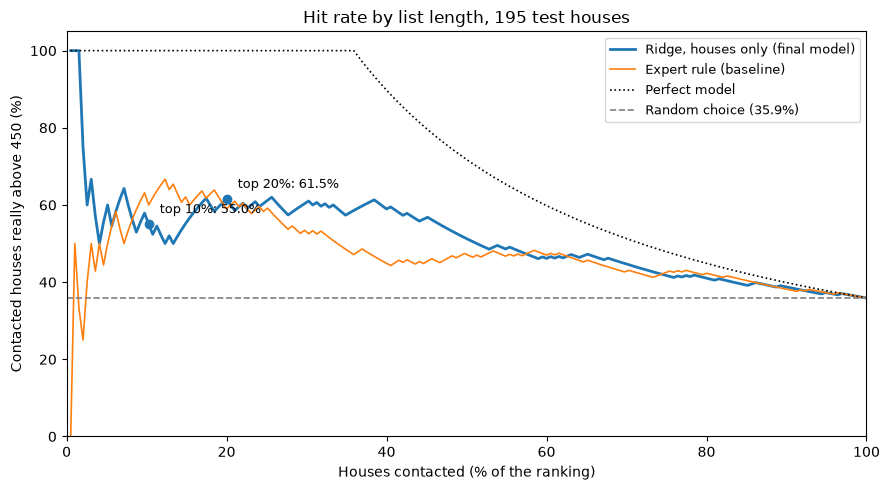

,list length (%),test houses on the list,of which above 450,hit rate model (%),hit rate expert rule (%),random (%),owners in target group
0,5,10,6,60.0,50.0,35.9,None
1,10,20,11,55.0,60.0,35.9,None
2,20,39,24,61.5,59.0,35.9,None
3,30,58,35,60.3,53.4,35.9,None
4,50,98,50,51.0,46.9,35.9,None
5,100,195,70,35.9,35.9,35.9,None


In [19]:
# task 13: number of undeclared houses in the target group (Person 5). None = the owner axis is not drawn yet
TARGET_GROUP_HOUSES = None

pred = pd.read_csv(TABLES / "evaluation_test_predictions.csv")
houses_test = pred[pred["house"]].reset_index(drop=True)
above = (houses_test["y"] > THRESHOLD).to_numpy()
n = len(houses_test)
base_rate = above.mean()   # random choice: share of test houses above 450

def hit_rate_curve(score):
    # for every list length k: share of the top k houses that are really above 450
    # (same ranking and tie-break as the selection measure in metrics.py)
    order = _top_positions(score.to_numpy(), 1.0)
    hits = np.cumsum(above[order])
    k = np.arange(1, n + 1)
    return k / n * 100, hits / k * 100

x, model_curve = hit_rate_curve(houses_test["pred"])
_, rule_curve = hit_rate_curve(houses_test["pred_expert_rule"])
perfect_curve = np.minimum(1, above.sum() / np.arange(1, n + 1)) * 100   # all problem houses first

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, model_curve, color="C0", linewidth=2, label="Ridge, houses only (final model)")
ax.plot(x, rule_curve, color="C1", linewidth=1.2, label="Expert rule (baseline)")
ax.plot(x, perfect_curve, color="black", linestyle=":", linewidth=1.2, label="Perfect model")
ax.axhline(base_rate * 100, color="grey", linestyle="--", linewidth=1.2,
           label=f"Random choice ({base_rate * 100:.1f}%)")
for top in (10, 20):   # the two list lengths from README decision 3
    i = int(round(top / 100 * n)) - 1
    ax.scatter(x[i], model_curve[i], color="C0", zorder=3)
    ax.annotate(f"top {top}%: {model_curve[i]:.1f}%", (x[i], model_curve[i]),
                textcoords="offset points", xytext=(8, 8), fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.set_xlabel("Houses contacted (% of the ranking)")
ax.set_ylabel("Contacted houses really above 450 (%)")
ax.set_title(f"Hit rate by list length, {n} test houses")
ax.legend(loc="upper right", fontsize=9)
if TARGET_GROUP_HOUSES is not None:   # second axis: what each list length means in owners
    owners = ax.secondary_xaxis("top", functions=(lambda p: p / 100 * TARGET_GROUP_HOUSES,
                                                  lambda o: o / TARGET_GROUP_HOUSES * 100))
    owners.set_xlabel("Owners contacted in the target group")
fig.tight_layout()
fig.savefig(FIGURES / "evaluation_hit_rate_curve.png", dpi=150)
plt.show()

# the same curve as a table, for the report
rows = []
for top in (5, 10, 20, 30, 50, 100):
    k = int(round(top / 100 * n))
    rows.append({
        "list length (%)": top,
        "test houses on the list": k,
        "of which above 450": int(round(model_curve[k - 1] / 100 * k)),
        "hit rate model (%)": round(model_curve[k - 1], 1),
        "hit rate expert rule (%)": round(rule_curve[k - 1], 1),
        "random (%)": round(base_rate * 100, 1),
        "owners in target group": None if TARGET_GROUP_HOUSES is None else int(round(top / 100 * TARGET_GROUP_HOUSES)),
    })
hit_rates = pd.DataFrame(rows)
hit_rates.to_csv(TABLES / "evaluation_hit_rate_curve.csv", index=False)
hit_rates